# Выбор оптимальной модели

В этом семинаре мы потренируемся в обучении, оценке и валидации моделей, подборе оптимальных гиперпараметров, смешении моделей. Мы будем решать задачу бинарной классификации, а именно, построить алгоритм, определяющий, превысит ли средний заработок человека порог $50000 в год.

## Загрузка и обработка набора данных
Загрузим набор данных из интернета с помощью функции pd.read_csv. Разделим данные на численные и категориальные, удалим из набора строчки с пропущенными значениями.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data')
# Назначаем имена колонок
columns = ('age workclass fnlwgt education educ-num marital-status occupation relationship '
           'race sex capital-gain capital-loss  hours-per-week native-country salary')

numeric_indices = np.array([0, 2, 4, 10, 11, 12])
categorical_indices = np.array([1, 3, 5, 6, 7, 8, 9, 13])

df.columns = columns.split() #этот метод разделит датасет по колонкам, как в массиве columns

df = df.replace('?', np.nan)

df = df.dropna()

df['salary'] = df['salary'].apply((lambda x: x==' >50K')) # Будем предсказывать 1 (True), если зарплата больше 50K, 0 (False) иначе

In [3]:
numeric_data = df[df.columns[numeric_indices]]

categorial_data = df[df.columns[categorical_indices]]
categorial_data.head()

,workclass,education,marital-status,occupation,relationship,race,sex,native-country
0,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States
1,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States
2,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States
3,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba
4,Private,Masters,Married-civ-spouse,Exec-managerial,Wife,White,Female,United-States


### One-hot кодирование
Поскольку все алгоритмы машинного обучения, которые мы изучили, работают лишь с числовыми признаками, необходимо придумать способ обработки категориальных признаков, переводящий их в числовые. 
Одним из способов сделать это является One-hot кодирование. Его суть состоит в следующем. Пусть некоторая категориальная переменная (скажем, color) принимает $n$ различных значений (Red, Yellow, Green). Тогда можно создать $n$ новыx переменныx, соответствующих различным значениям категориального признака, каждая из которых равна 1 в том случае, если изначальный категориальный признак принимает такое значение, и 0 иначе. Принцип работы иллюстрирован на картинке.

![alt text](one_hot-1.png)

В Pandas One-hot кодирование выполняется функцией pd.get_dummies. Сгенерируем One-hot признаки для нашего датасета. Сохраним полную матрицу объекты признаки в переменную X.

In [4]:
dummy_features = pd.get_dummies(categorial_data)

In [5]:
X = pd.concat([numeric_data, dummy_features], axis=1)
X.head()

,age,fnlwgt,educ-num,capital-gain,capital-loss,hours-per-week,workclass_ ?,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
0,50,83311,13,0,0,13,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,38,215646,9,0,0,40,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,53,234721,7,0,0,40,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,28,338409,13,0,0,40,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,37,284582,14,0,0,40,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


Выделим целевую переменную в y и вычислим процент единиц в значениях y.

In [6]:
y = df['salary']
y.mean()

np.float64(0.24081695331695332)

Видим, что обучающая выборка не сбалансированная. Поэтому для оценки качества предсказания метрика accuracy (процент верно угаданных лейблов) не подойдёт. Вместо этого будем использовать метрику F1-score (https://en.wikipedia.org/wiki/F1_score).

F1-score --- метрика, которая учитывает возможную разбалансировку классов при решении задачи классификации. Она вычисляется по формуле 
$${\displaystyle F_{1}=\left({\frac {2}{\mathrm {recall} ^{-1}+\mathrm {precision} ^{-1}}}\right)=2\cdot {\frac {\mathrm {precision} \cdot \mathrm {recall} }{\mathrm {precision} +\mathrm {recall} }}},$$

где $$\mathrm{precision} = \frac{\mathrm{True Positive}}{\mathrm{True Positive} + \mathrm{False Positive}}, \,\,\,\, \mathrm{recall} = \frac{\mathrm{True Positive}}{\mathrm{True Positive} + \mathrm{False Negative}}.$$
![alt text](F1-1.png)
![alt text](https://drive.google.com/uc?id=1NzO701z8udWBo6z7GQ8vkNIblT61sjGK)

## Разбиение данных на train и test

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, train_size=0.8)

## Тестирование

Напишем функцию, визуализирующую поиск оптимального гиперпараметра модели по сетке. Для этого используем метод GridSearchCV из sklearn.model_selection.

In [9]:
from sklearn.model_selection import GridSearchCV

In [10]:
def search_and_draw(X, y, model, param_name, grid, draw=True):
    parameters = {param_name: grid}
    
    CV_model = GridSearchCV(estimator=model, param_grid=parameters, cv=5, scoring='f1', n_jobs=-1)
    CV_model.fit(X, y)
    means = CV_model.cv_results_['mean_test_score']
    error = CV_model.cv_results_['std_test_score']
    
    if draw:
        plt.figure(figsize=(15,8))
        plt.title('choose ' + param_name)


        plt.plot(grid, means, label='mean values of score')

        plt.fill_between(grid, means - 2 * error, means + 2 * error, color='green', label='deviation area between errors')
        plt.legend()
        plt.xlabel('parameter')
        plt.ylabel('f1')
        plt.show()
        
    return means, error

Протестируем функцию на Knn и решающем дереве.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [12]:
models = [KNeighborsClassifier(), DecisionTreeClassifier()]
param_names = ['n_neighbors', 'max_depth']
grids = [np.array(np.linspace(4, 19, 6), dtype='int'), np.arange(1, 21)]

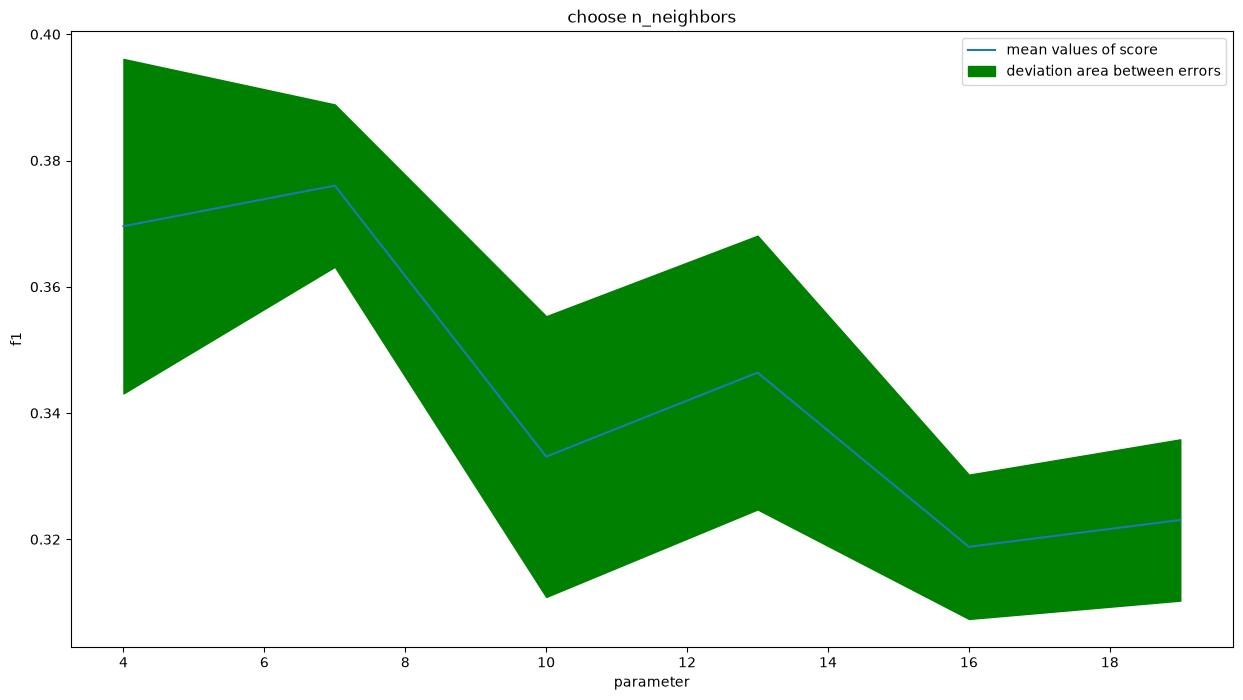

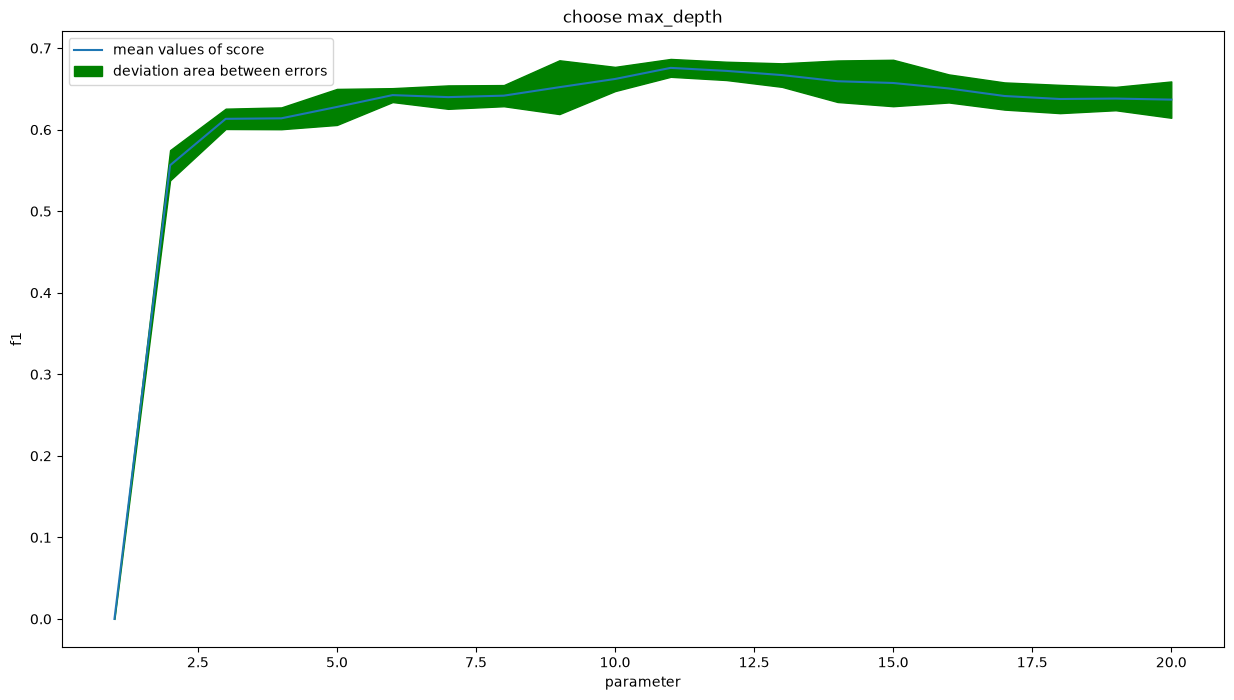

In [13]:
for model, param_name, grid in zip(models, 
                                   param_names, 
                                   grids):
    search_and_draw(X_train, y_train, model, param_name, grid)

### Нормировка данных

Нормируем признаки и проделаем тот же эксперимент с алгоритмом ближайших соседей. Посмотрим, изменилось ли качество предсказания.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

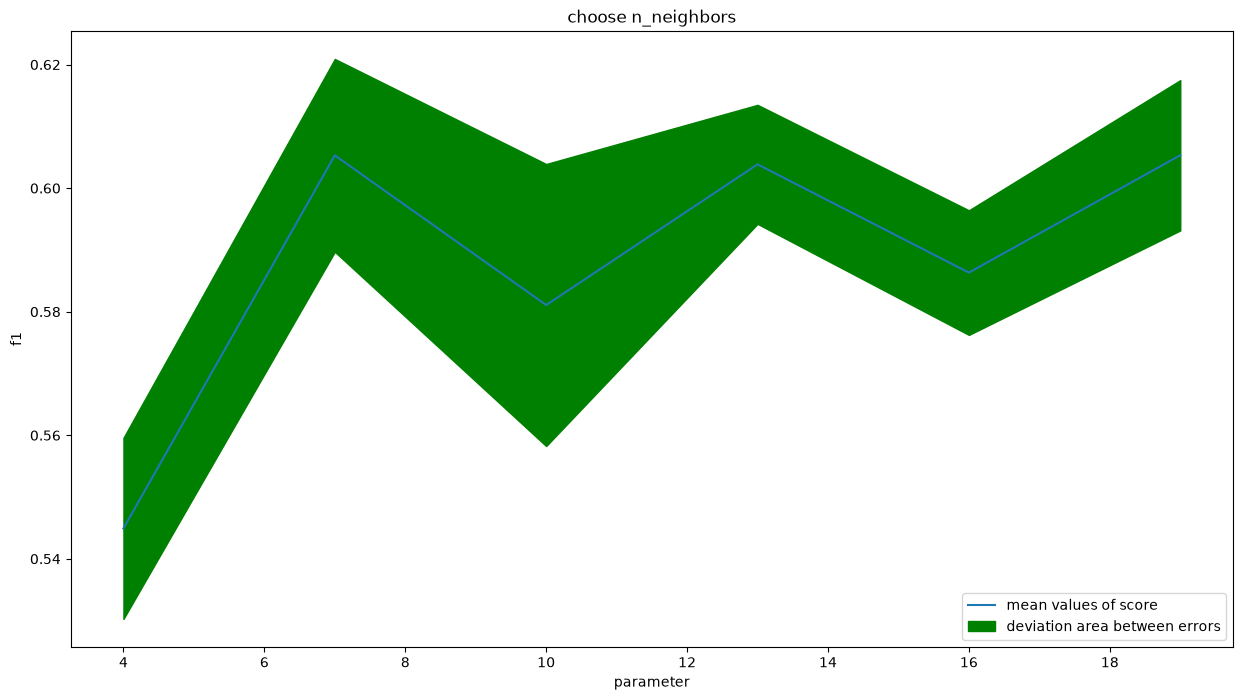

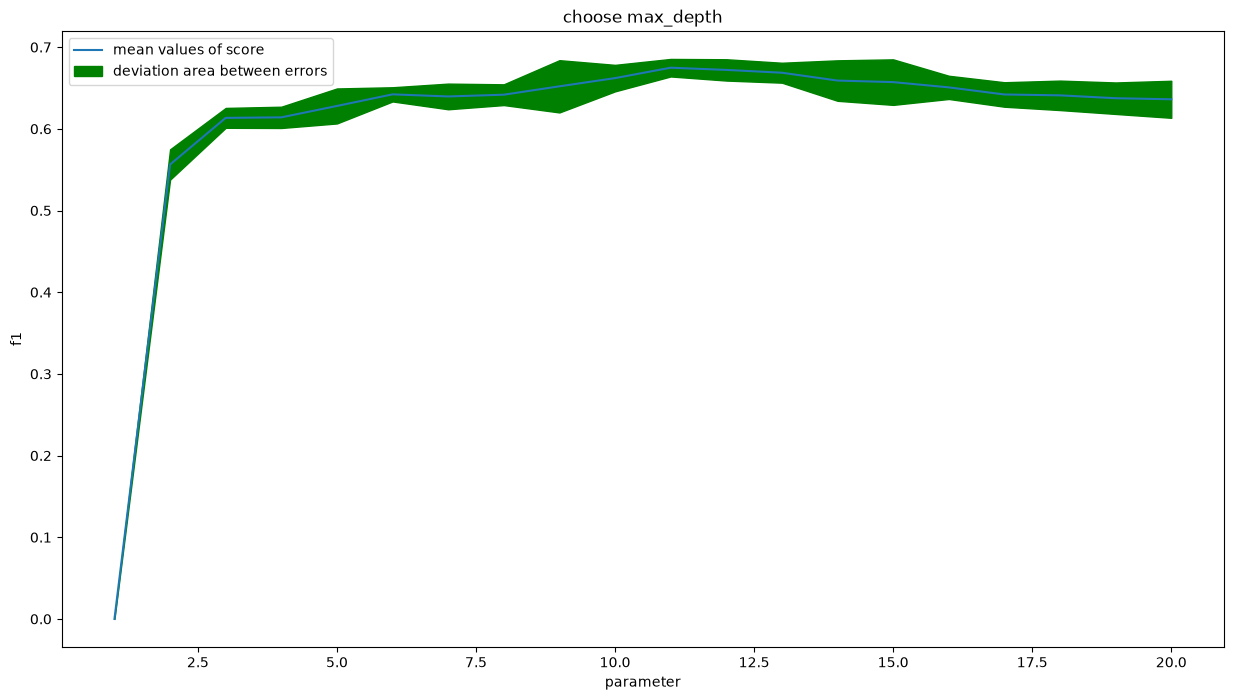

In [15]:
models = [KNeighborsClassifier(), DecisionTreeClassifier()]
param_names = ['n_neighbors', 'max_depth']
grids = [np.array(np.linspace(4, 19, 6), dtype='int'), np.arange(1, 21)]

for model, param_name, grid in zip(models, 
                                   param_names, 
                                   grids):
    search_and_draw(X_train, y_train, model, param_name, grid)

Подберём параметр n_estimators в алгоритме случайный лес. Известно, что случайный лес не переобучается. Поэтому график качества будет монотонно возрастать. Следовательно, необходимо найти минимальное значение n_estimators, при котором качество не изменяется. 
Поскольку каждое дерево обучается независимо от остальных, достаточно обучить сразу лес из большого количества деревьев, а затем рассмотреть подмножества нужного размера из исходного множества деревьев.

Мы не будем так делать ввиду излишней сложности получаемого кода.

In [16]:
from sklearn.ensemble import RandomForestClassifier

In [17]:
models = [RandomForestClassifier(n_jobs=-1)]
param_names = ['n_estimators']
grids = [[10, 20, 30, 50, 75, 100, 125, 150, 200]]
param_scales = ['ordinary']

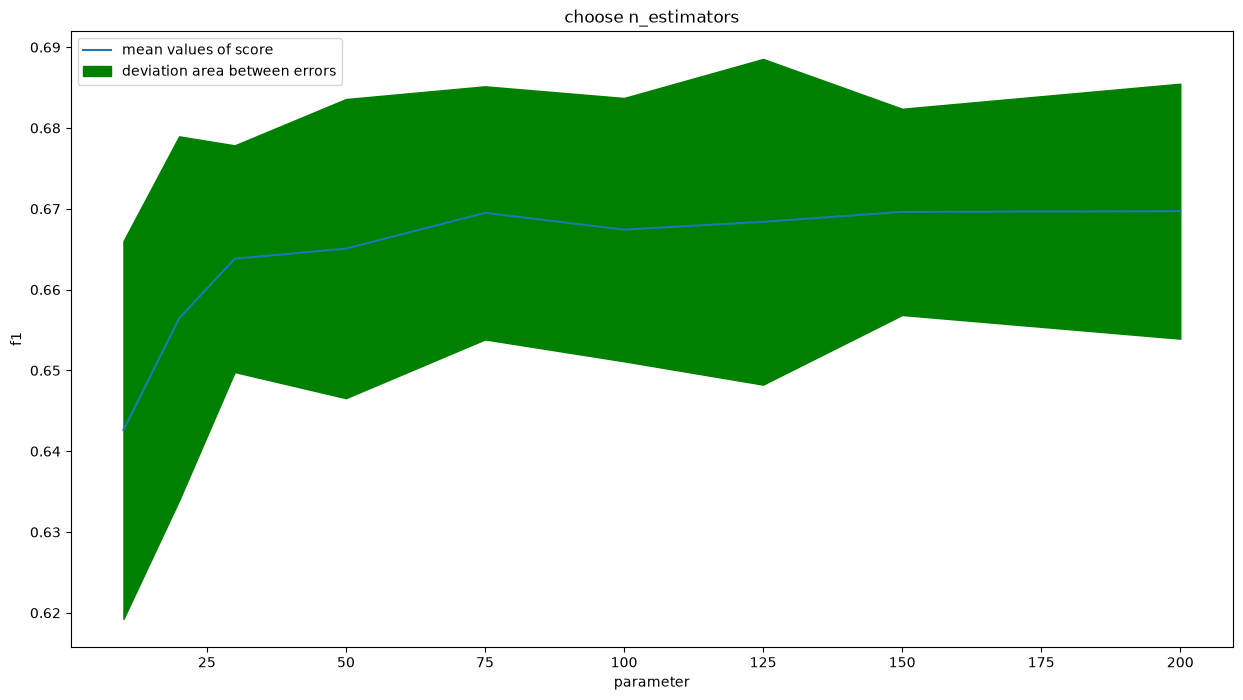

In [18]:
for model, param_name, grid, param_scale in zip(models, 
                                                param_names, 
                                                grids, 
                                                param_scales):
    search_and_draw(X_train, y_train, model, param_name, grid, param_scale)

Как и следовало ожидать, ни один из наших алгоритмов не побил случайный лес. Итак, видим, что на больших выборках бэггинг работает. Вычислим итоговое качество на test.

In [19]:
from sklearn.metrics import f1_score

In [20]:
model = RandomForestClassifier(n_estimators=75, n_jobs=-1)

model.fit(X_train, y_train)
y_predicted = model.predict(X_test)

f1_score(y_test, y_predicted)

0.6800554016620498

### Что ещё можно делать.

Мы подбирали оптимальный одномерный параметр для алгоритма. Можно также:

* Искать по сетке не только численные гиперпараметры, но и категориальные, например, метрику в алгоритме ближайших соседей или критерий ветвления в решающем дереве.

* Искать оптимальный параметр по многомерной сетке. Перебрать все возможные варианты здесь не выйдет, потому что на это уйдёт слишком много времени. Зато можно перебирать случайные точки по сетке. Эта процедура называется Grid Random Search.

# Бустинг

Попробуем в пару-тройку строк побить всё то качество, которое мы так усердно искали.

In [22]:
import xgboost

ModuleNotFoundError: No module named 'xgboost'

In [23]:
boosting_model = xgboost.XGBClassifier(n_estimators=500)

boosting_model.fit(X_train, y_train)

y_predicted = boosting_model.predict(X_test)

NameError: name 'xgboost' is not defined

In [24]:
f1_score(y_test, y_predicted)

0.6800554016620498